In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

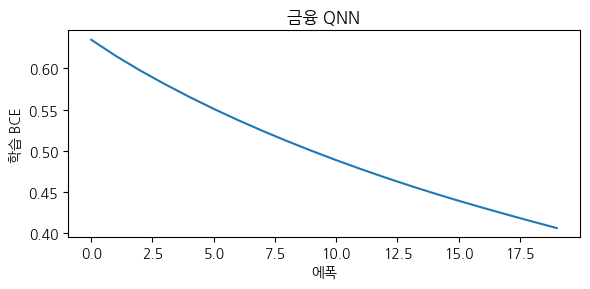

바스켓별 비용: [0.19609462 0.23040283 0.22161148 0.18476157 0.19851889]

========== 금융 포트폴리오 선정 결과 ==========
QAOA 추천 바스켓: ['D']
VQE 추천 바스켓: ['A']


In [13]:
import numpy as np
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from qiskit_optimization import QuadraticProgram

# ----------------------------------------------------
# 1) 금융 데이터 정의
# ----------------------------------------------------
fin_data = np.array([
    #  ret  vol  spr  liq  sent  mdd  mom
    [ 0.8, 9.5,  8,  45,  0.3,  8.0,  0.5],
    [ 0.6, 7.8, 10,  60,  0.2,  6.5,  0.3],
    [ 1.1,12.2, 12,  38,  0.1, 10.5,  0.9],
    [ 0.4, 6.9,  7,  72,  0.5,  5.8, -0.2],
    [ 0.9,10.1, 11,  40, -0.1,  9.4,  0.8],
    [ 0.7, 8.6,  9,  55,  0.4,  7.2,  0.4],
    [ 1.2,13.0, 14,  30, -0.2, 12.1,  1.1],
    [ 0.5, 7.2,  8,  68,  0.3,  6.2,  0.1],
    [ 0.3, 6.1,  6,  80,  0.6,  5.0, -0.3],
    [ 1.0,11.4, 13,  35,  0.0, 11.2,  0.7],
    [ 0.9,10.8, 12,  42,  0.1, 10.0,  0.6],
    [ 0.5, 7.6,  9,  63,  0.2,  6.7,  0.2],
    [ 0.2, 5.4,  5,  85,  0.7,  4.3, -0.4],
    [ 1.3,13.8, 15,  28, -0.3, 12.8,  1.3],
    [ 0.6, 8.2,  9,  58,  0.1,  7.0,  0.3],
    [ 0.8, 9.1, 10,  50,  0.0,  8.1,  0.5],
    [ 0.7, 8.9,  9,  53,  0.2,  7.6,  0.4],
    [ 1.1,12.0, 13,  33, -0.1, 11.0,  0.9],
    [ 0.4, 6.7,  7,  74,  0.4,  5.6, -0.1],
    [ 0.5, 7.0,  8,  70,  0.5,  6.0,  0.0],
    [ 1.4,14.4, 16,  25, -0.4, 13.5,  1.5],
    [ 0.3, 5.8,  6,  82,  0.6,  4.8, -0.3],
    [ 0.9,10.3, 11,  44,  0.0,  9.6,  0.7],
    [ 0.6, 8.0, 10,  60,  0.3,  6.9,  0.2],
    [ 1.0,11.2, 12,  37, -0.2, 10.7,  0.8],
    [ 0.2, 5.1,  5,  88,  0.7,  4.1, -0.5],
    [ 0.7, 8.4,  9,  57,  0.2,  7.1,  0.3],
    [ 1.2,12.7, 14,  31, -0.1, 11.9,  1.0],
    [ 0.5, 7.3,  8,  66,  0.4,  6.3,  0.1],
    [ 0.8, 9.6, 10,  48,  0.1,  8.4,  0.5],
], dtype=np.float32)

# ----------------------------------------------------
# 2) 팩터 가공 및 QNN 학습
# ----------------------------------------------------
def minmax(v):
    return (v - v.min()) / max(float(np.ptp(v)), 1e-12)

ret, vol, spr, liq, sent, mdd, mom = fin_data.T
risk = 0.6 * minmax(vol) + 0.4 * minmax(mdd)
friction = 0.5 * minmax(spr) + 0.5 * (1 - minmax(liq))
adjustment = 0.2 * (1 - minmax(sent)) + 0.2 * (1 - minmax(mom))
cost = 0.5 * risk + 0.3 * friction + 0.1 * adjustment - 0.4 * minmax(ret)

train, test = train_test_split(np.arange(len(cost)), test_size=0.3, random_state=42)
threshold = np.median(cost[train])
labels = (cost <= threshold).astype(float)

probabilities = train_classifier(np.column_stack([risk, friction]), labels, '금융 QNN', (train, test))

# ----------------------------------------------------
# 3) 바스켓별 비용 산출 및 최적화 문제 정의
# ----------------------------------------------------
liquidity = liq.reshape(5, 6).mean(axis=1)
basket_cost = cost.reshape(5, 6).mean(axis=1) + 0.2 * np.maximum(0, 50 - liquidity) / 50

print('바스켓별 비용:', basket_cost)

problem = QuadraticProgram()
for name in 'ABCDE':
    problem.binary_var(name)

problem.minimize(linear=basket_cost)
problem.linear_constraint({name: 1 for name in 'ABCDE'}, '==', 1, 'one_basket')

# ----------------------------------------------------
# 4) QAOA 및 VQE 알고리즘 실행
# ----------------------------------------------------
qaoa_result = run_qaoa(problem, '금융 QAOA')
vqe_result = run_vqe(problem, '금융 VQE')  # 딕셔너리 반환 형태에 맞춤

# ----------------------------------------------------
# 5) 최종 결과 출력
# ----------------------------------------------------
print('\n========== 금융 포트폴리오 선정 결과 ==========')
print('QAOA 추천 바스켓:', np.array(list('ABCDE'))[qaoa_result["x"] > 0.5])
print('VQE 추천 바스켓:', np.array(list('ABCDE'))[vqe_result["x"] > 0.5])
print('===============================================')